In [1]:
import os
print('Working directory:', os.getcwd())

Working directory: E:\.MSc\Research2\Research\Data_Prep_ipynb


# 📈 HeartCycle — Notebook 4: EDA & Bias Analysis (Answers RQ1)

---

## Purpose
This notebook **directly answers RQ1** and provides deep exploratory analysis:

> **RQ1:** How strong is the timing bias between the ICG-determined B-point and X-point locations and ECHO-validated aortic valve events?

We perform:
1. **Bias distribution analysis** — B-point and X-point bias histograms
2. **Per-subject bias statistics** — systematic vs. random error decomposition
3. **Bland-Altman analysis** — clinical agreement assessment
4. **Correlation analysis** — Pearson r and Lin's Concordance Correlation Coefficient
5. **Clinical threshold analysis** — % beats within ±5ms, ±10ms, ±15ms
6. **Beat-level signal template analysis** — mean waveforms across splits
7. **Full dataset statistics** — sets context for RQ2–RQ5

---
**Requires:** `.npz` files in `./output/preprocessed/` from Notebook 2,  
and final arrays in `./output/final_dataset/` from Notebook 3.

In [2]:
PREPROCESSED_DIR  = './output/preprocessed'
FINAL_DATASET_DIR = './output/final_dataset'
EDA_OUTPUT_DIR    = './output/eda'

import os
os.makedirs(f'{EDA_OUTPUT_DIR}/figures', exist_ok=True)
print('Directories ready.')

Directories ready.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from scipy import stats
import json, warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

prep_dir  = Path(PREPROCESSED_DIR)
final_dir = Path(FINAL_DATASET_DIR)
eda_dir   = Path(EDA_OUTPUT_DIR)

rows = []
for split in ['train', 'val', 'test']:
    d = final_dir / split
    try:
        biases = np.load(d / 'biases.npy')
        y_pep  = np.load(d / 'y_pep.npy')
        y_lvet = np.load(d / 'y_lvet.npy')
        y_avo  = np.load(d / 'y_avo.npy')
        y_avc  = np.load(d / 'y_avc.npy')
        meta   = pd.read_csv(d / 'meta.csv')
    except FileNotFoundError:
        continue
    icg_pep  = y_pep  + biases[:, 2]
    icg_lvet = y_lvet + biases[:, 3]
    for i in range(len(biases)):
        rows.append({
            'subject_id': meta.loc[i, 'subject_id'], 'record_id': meta.loc[i, 'record_id'],
            'split': split,
            'b_bias_ms': biases[i,0], 'x_bias_ms': biases[i,1],
            'pep_bias_ms': biases[i,2], 'lvet_bias_ms': biases[i,3],
            'gt_pep_ms': y_pep[i], 'gt_lvet_ms': y_lvet[i],
            'gt_avo_ms': y_avo[i], 'gt_avc_ms': y_avc[i],
            'icg_pep_ms': icg_pep[i], 'icg_lvet_ms': icg_lvet[i],
        })
df = pd.DataFrame(rows)

print(f'Loaded {len(df):,} filtered beat-level records from {df["subject_id"].nunique()} subjects')
print(df.groupby('split').size())
df.head(3)

Loaded 279 filtered beat-level records from 13 subjects
split
test      69
train    166
val       44
dtype: int64


,subject_id,record_id,split,b_bias_ms,x_bias_ms,pep_bias_ms,lvet_bias_ms,gt_pep_ms,gt_lvet_ms,gt_avo_ms,gt_avc_ms,icg_pep_ms,icg_lvet_ms
0,CHC01,s0000060,train,-0.023796,4.408334,14.110984,4.432129,51.470589,262.938904,345.588226,608.527161,65.581573,267.371033
1,CHC01,s0000060,train,21.820864,29.606190,21.892252,7.785326,58.823528,254.540970,1095.588257,1350.129150,80.715782,262.326294
2,CHC01,s0000077,train,14.988505,36.907330,13.972638,21.918825,55.783554,257.105957,452.842377,709.948303,69.756195,279.024780


In [4]:
import time
p = final_dir / 'train' / 'biases.npy'
print('Reading from:', p.resolve())
print('File last modified:', time.ctime(os.path.getmtime(p)))

Reading from: E:\.MSc\Research2\Research\Data_Prep_ipynb\output\final_dataset\train\biases.npy
File last modified: Wed Sep  9 19:55:50 2026


In [5]:
import datetime
print('CANARY — this cell ran at:', datetime.datetime.now())

CANARY — this cell ran at: 2026-09-09 19:56:00.845922


## 1. RQ1 Core Analysis — Bias Distributions
The fundamental question: how far off are the ICG B/X estimates from ECHO ground truth?

In [6]:
def bias_stats(series, label):
    arr = series.dropna().values
    if len(arr) == 0:
        return {'label': label, 'n': 0}
    _, p = stats.shapiro(arr[:min(5000, len(arr))])
    return {
        'label': label, 'n': len(arr),
        'mean_ms': np.mean(arr), 'std_ms': np.std(arr),
        'mae_ms': np.mean(np.abs(arr)), 'rmse_ms': np.sqrt(np.mean(arr**2)),
        'median_ms': np.median(arr),
        'iqr_ms': np.percentile(arr, 75) - np.percentile(arr, 25),
        'loa_upper': np.mean(arr) + 1.96*np.std(arr),
        'loa_lower': np.mean(arr) - 1.96*np.std(arr),
        'pct_5ms':  np.mean(np.abs(arr) < 5)*100,
        'pct_10ms': np.mean(np.abs(arr) < 10)*100,
        'pct_15ms': np.mean(np.abs(arr) < 15)*100,
        'normal_p': p,
    }

df_b    = df.dropna(subset=['b_bias_ms'])
df_x    = df.dropna(subset=['x_bias_ms'])
df_pep  = df.dropna(subset=['pep_bias_ms','gt_pep_ms','icg_pep_ms'])
df_lvet = df.dropna(subset=['lvet_bias_ms','gt_lvet_ms','icg_lvet_ms'])
df_pep  = df_pep[(df_pep['gt_pep_ms']>50) & (df_pep['gt_pep_ms']<250)]
df_lvet = df_lvet[(df_lvet['gt_lvet_ms']>150) & (df_lvet['gt_lvet_ms']<500)]

res = {
    'B-point':  bias_stats(df_b['b_bias_ms'],      'B-point (ICG B − ECHO AVO)'),
    'X-point':  bias_stats(df_x['x_bias_ms'],      'X-point (ICG X − ECHO AVC)'),
    'PEP':      bias_stats(df_pep['pep_bias_ms'],  'PEP (ICG − ECHO)'),
    'LVET':     bias_stats(df_lvet['lvet_bias_ms'],'LVET (ICG − ECHO)'),
}


# Print summary table
summary_rows = []
for name, r in res.items():
    if r.get('n', 0) == 0: continue
    summary_rows.append({
        'Parameter': name, 'N beats': r['n'],
        'Mean bias (ms)': f"{r['mean_ms']:.2f}",
        'Std (ms)': f"{r['std_ms']:.2f}",
        'MAE (ms)': f"{r['mae_ms']:.2f}",
        '95% LoA': f"[{r['loa_lower']:.1f}, {r['loa_upper']:.1f}]",
        '% within ±15ms': f"{r['pct_15ms']:.1f}%",
        'Clinical target\nMAE<15ms': '✅' if r['mae_ms'] < 15 else '❌',
    })

print('\n=== RQ1: ICG TIMING BIAS SUMMARY ===')
summary_df = pd.DataFrame(summary_rows)
pd.set_option('display.max_colwidth', None)
print(summary_df.to_string(index=False))
summary_df.to_csv(f'{EDA_OUTPUT_DIR}/bias_summary.csv', index=False)


=== RQ1: ICG TIMING BIAS SUMMARY ===
Parameter  N beats Mean bias (ms) Std (ms) MAE (ms)         95% LoA % within ±15ms Clinical target\nMAE<15ms
  B-point      279          29.39    59.65    43.75  [-87.5, 146.3]          40.1%                         ❌
  X-point      279          12.88    45.81    41.95  [-76.9, 102.7]           7.9%                         ❌
      PEP      279          28.68    59.05    43.29  [-87.1, 144.4]          40.9%                         ❌
     LVET      279         -16.47    72.49    60.18 [-158.6, 125.6]          13.3%                         ❌


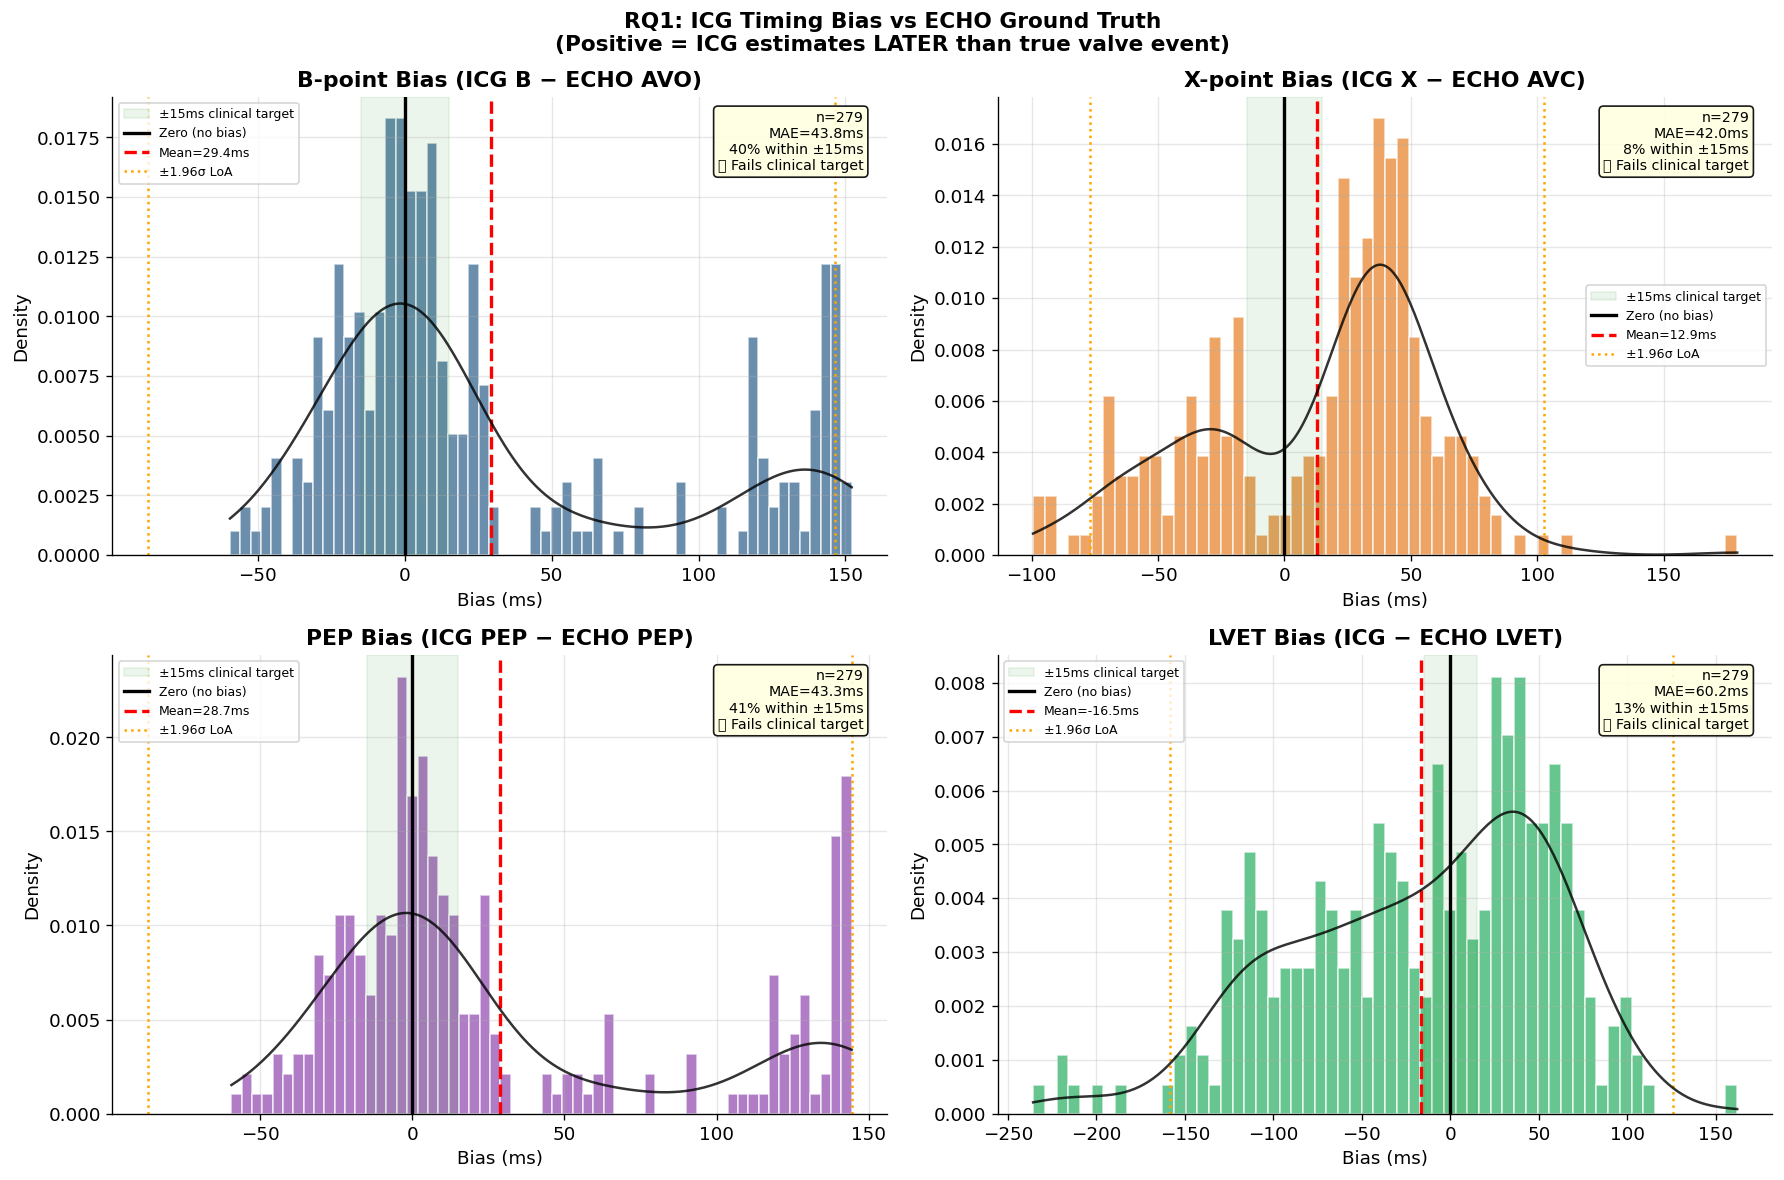

Saved fig1_bias_distributions.png


In [7]:
# Figure 1: Bias distributions with clinical threshold
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('RQ1: ICG Timing Bias vs ECHO Ground Truth\n(Positive = ICG estimates LATER than true valve event)', 
             fontsize=13, fontweight='bold')

datasets = [
    (df_b['b_bias_ms'],     'B-point Bias (ICG B − ECHO AVO)', '#2C5F8A',  axes[0,0]),
    (df_x['x_bias_ms'],     'X-point Bias (ICG X − ECHO AVC)', '#E67E22',  axes[0,1]),
    (df_pep['pep_bias_ms'], 'PEP Bias (ICG PEP − ECHO PEP)',  '#8E44AD',  axes[1,0]),
    (df_lvet['lvet_bias_ms'],'LVET Bias (ICG − ECHO LVET)',   '#27AE60',  axes[1,1]),
]

for data, title, color, ax in datasets:
    arr = data.dropna().values
    if len(arr) == 0:
        ax.set_title(f'{title}\n(no data)'); continue
    
    ax.hist(arr, bins=60, color=color, alpha=0.7, edgecolor='white', density=True)
    
    # Clinical ±15ms zone
    ax.axvspan(-15, 15, alpha=0.08, color='green', label='±15ms clinical target')
    ax.axvline(0,                        color='black', linewidth=2,   linestyle='-',  label='Zero (no bias)')
    ax.axvline(np.mean(arr),             color='red',   linewidth=2,   linestyle='--', label=f'Mean={np.mean(arr):.1f}ms')
    ax.axvline(np.mean(arr)+1.96*np.std(arr), color='orange', linewidth=1.5, linestyle=':', label=f'±1.96σ LoA')
    ax.axvline(np.mean(arr)-1.96*np.std(arr), color='orange', linewidth=1.5, linestyle=':')
    
    # KDE overlay
    from scipy.stats import gaussian_kde
    try:
        kde = gaussian_kde(arr)
        x_range = np.linspace(arr.min(), arr.max(), 300)
        ax.plot(x_range, kde(x_range), color='black', linewidth=1.5, alpha=0.8)
    except:
        pass
    
    mae = np.mean(np.abs(arr))
    pct15 = np.mean(np.abs(arr) < 15)*100
    status = '✅ Meets' if mae < 15 else '❌ Fails'
    ax.text(0.97, 0.97,
            f'n={len(arr):,}\nMAE={mae:.1f}ms\n{pct15:.0f}% within ±15ms\n{status} clinical target',
            transform=ax.transAxes, ha='right', va='top', fontsize=8.5,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Bias (ms)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=7.5)

plt.tight_layout()
plt.savefig(f'{EDA_OUTPUT_DIR}/figures/fig1_bias_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved fig1_bias_distributions.png')

## 2. Per-Subject Bias Analysis — Systematic vs. Random Error

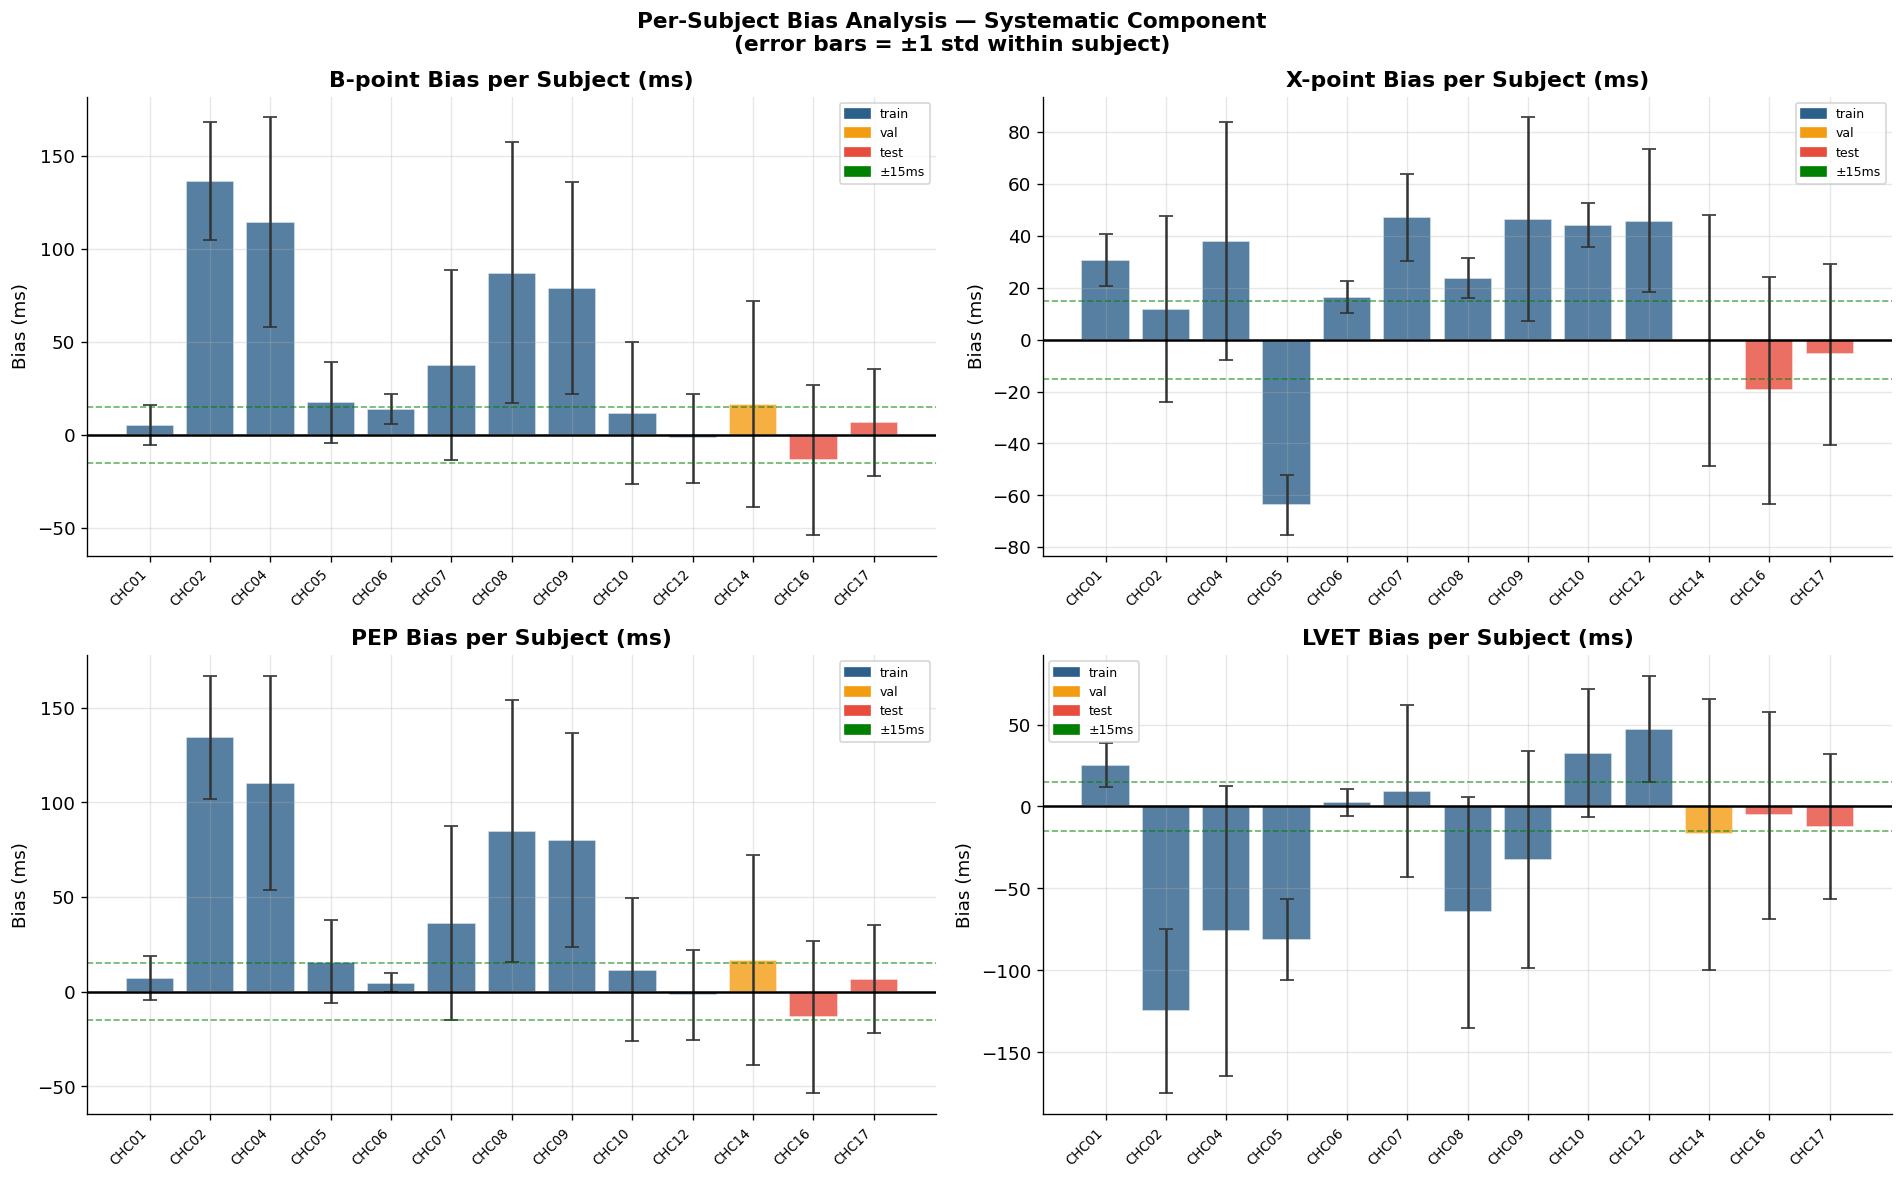


Key insight: If bias varies a lot across subjects (high inter-subject std),
subject-level normalization or subject-adaptive models may be needed.

Inter-subject std of B-point bias: 48.4ms
Intra-subject mean std of B-point:  37.9ms


In [8]:
# Compute per-subject statistics
subj_stats = []
for subj, grp in df.groupby('subject_id'):
    row = {'subject_id': subj, 'n_beats': len(grp), 'split': grp['split'].iloc[0]}
    for col, nm in [('b_bias_ms','B'), ('x_bias_ms','X'),
                    ('pep_bias_ms','PEP'), ('lvet_bias_ms','LVET')]:
        arr = grp[col].dropna().values
        row[f'{nm}_mean'] = float(np.mean(arr)) if len(arr) else np.nan
        row[f'{nm}_std']  = float(np.std(arr))  if len(arr) else np.nan
        row[f'{nm}_mae']  = float(np.mean(np.abs(arr))) if len(arr) else np.nan
        row[f'{nm}_n']    = len(arr)
    subj_stats.append(row)
subj_df = pd.DataFrame(subj_stats)
subj_df.to_csv(f'{EDA_OUTPUT_DIR}/bias_per_subject.csv', index=False)


# Plot
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Per-Subject Bias Analysis — Systematic Component\n(error bars = ±1 std within subject)',
             fontsize=13, fontweight='bold')

split_colors = {'train': '#2C5F8A', 'val': '#F39C12', 'test': '#E74C3C'}

for ax, (mn, sn, label, color_col) in zip(axes.flat, [
    ('B_mean', 'B_std',    'B-point Bias per Subject (ms)', 'split'),
    ('X_mean', 'X_std',    'X-point Bias per Subject (ms)', 'split'),
    ('PEP_mean','PEP_std', 'PEP Bias per Subject (ms)', 'split'),
    ('LVET_mean','LVET_std','LVET Bias per Subject (ms)', 'split'),
]):
    valid = subj_df.dropna(subset=[mn])
    x_pos = range(len(valid))
    bar_colors = [split_colors.get(s, '#888') for s in valid['split']]
    
    ax.bar(x_pos, valid[mn], yerr=valid[sn].fillna(0),
           color=bar_colors, alpha=0.8, edgecolor='white',
           error_kw=dict(ecolor='#333', capsize=4, linewidth=1.5))
    ax.axhline(0,  color='black', linewidth=1.5)
    ax.axhline(15, color='green', linewidth=1, linestyle='--', alpha=0.6, label='±15ms')
    ax.axhline(-15,color='green', linewidth=1, linestyle='--', alpha=0.6)
    
    ax.set_xticks(list(x_pos))
    ax.set_xticklabels(valid['subject_id'], rotation=45, ha='right', fontsize=8)
    ax.set_title(label, fontweight='bold')
    ax.set_ylabel('Bias (ms)')
    ax.legend(fontsize=8)
    
    # Add split legend
    import matplotlib.patches as mpatches
    patches = [mpatches.Patch(color=c, label=s) for s, c in split_colors.items()]
    ax.legend(handles=patches + [mpatches.Patch(color='green', label='±15ms')], fontsize=7.5)

plt.tight_layout()
plt.savefig(f'{EDA_OUTPUT_DIR}/figures/fig2_per_subject_bias.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey insight: If bias varies a lot across subjects (high inter-subject std),')
print('subject-level normalization or subject-adaptive models may be needed.')
print(f'\nInter-subject std of B-point bias: {subj_df["B_mean"].std():.1f}ms')
print(f'Intra-subject mean std of B-point:  {subj_df["B_std"].mean():.1f}ms')

## 3. Bland-Altman Analysis
Standard clinical method to assess agreement between two measurement techniques.
Bias = mean of differences; LoA = 95% limits of agreement = mean ± 1.96 × SD

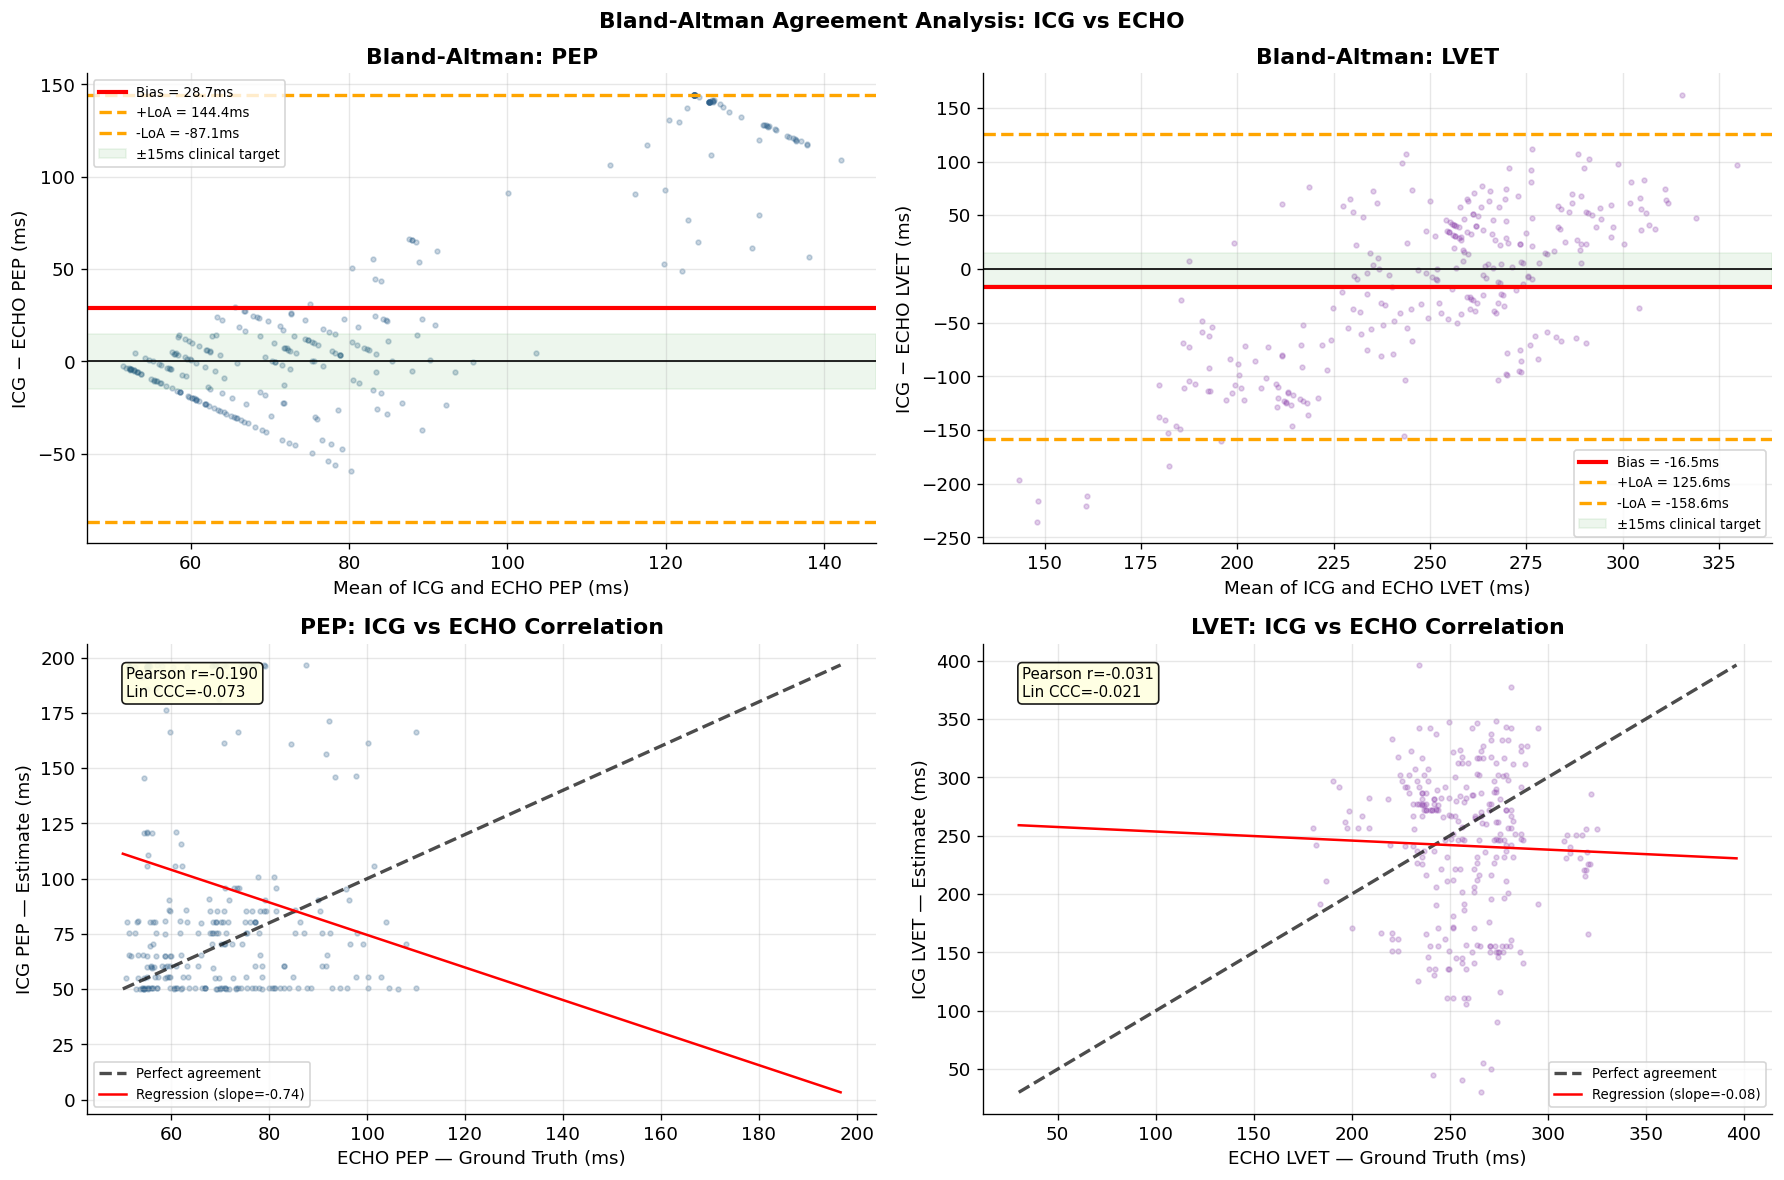


=== CORRELATION RESULTS ===
  PEP: r=-0.190, CCC=-0.073, Bias=28.7ms, LoA=[-87.1, 144.4]
  LVET: r=-0.031, CCC=-0.021, Bias=-16.5ms, LoA=[-158.6, 125.6]


In [9]:
def bland_altman_plot(ax, method1, method2, label, color='steelblue', max_pts=2000):
    diff = method1 - method2
    mean = (method1 + method2) / 2
    m_diff = np.mean(diff)
    s_diff = np.std(diff)
    loa_u = m_diff + 1.96*s_diff
    loa_l = m_diff - 1.96*s_diff
    
    # Subsample for plot clarity
    idx = np.random.choice(len(diff), min(max_pts, len(diff)), replace=False)
    ax.scatter(mean[idx], diff[idx], alpha=0.25, s=8, color=color)
    
    ax.axhline(m_diff, color='red',    linewidth=2.5, label=f'Bias = {m_diff:.1f}ms')
    ax.axhline(loa_u,  color='orange', linewidth=2,   linestyle='--', label=f'+LoA = {loa_u:.1f}ms')
    ax.axhline(loa_l,  color='orange', linewidth=2,   linestyle='--', label=f'-LoA = {loa_l:.1f}ms')
    ax.axhline(0,      color='black',  linewidth=1)
    ax.axhspan(-15, 15, alpha=0.07, color='green', label='±15ms clinical target')
    
    ax.set_xlabel(f'Mean of ICG and ECHO {label} (ms)')
    ax.set_ylabel(f'ICG − ECHO {label} (ms)')
    ax.set_title(f'Bland-Altman: {label}', fontweight='bold')
    ax.legend(fontsize=8)
    
    return m_diff, loa_u, loa_l, s_diff

def lins_ccc(x, y):
    mx, my = np.mean(x), np.mean(y)
    vx, vy = np.var(x), np.var(y)
    cov = np.cov(x, y)[0,1]
    return 2*cov / (vx + vy + (mx-my)**2)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Bland-Altman Agreement Analysis: ICG vs ECHO', fontsize=13, fontweight='bold')

ba_results = {}
plot_datasets = [
    (df_pep,  'icg_pep_ms',  'gt_pep_ms',   'PEP',  '#2C5F8A', axes[0,0]),
    (df_lvet, 'icg_lvet_ms', 'gt_lvet_ms',  'LVET', '#8E44AD', axes[0,1]),
]

for ds, icg_col, gt_col, label, color, ax in plot_datasets:
    if len(ds) > 10:
        m, lu, ll, s = bland_altman_plot(ax, ds[icg_col].values, ds[gt_col].values, label, color)
        r, p = stats.pearsonr(ds[icg_col].values, ds[gt_col].values)
        ccc  = lins_ccc(ds[icg_col].values, ds[gt_col].values)
        ba_results[label] = {'bias_mean':m, 'loa_upper':lu, 'loa_lower':ll, 
                              'pearson_r':r, 'pearson_p':p, 'ccc':ccc, 'n':len(ds)}

# Scatter correlation plots
for ax, ds, icg_col, gt_col, label, color in [
    (axes[1,0], df_pep,  'icg_pep_ms',  'gt_pep_ms',  'PEP',  '#2C5F8A'),
    (axes[1,1], df_lvet, 'icg_lvet_ms', 'gt_lvet_ms', 'LVET', '#8E44AD'),
]:
    if len(ds) > 10:
        idx = np.random.choice(len(ds), min(2000, len(ds)), replace=False)
        x_s = ds[gt_col].values[idx]
        y_s = ds[icg_col].values[idx]
        ax.scatter(x_s, y_s, alpha=0.25, s=8, color=color)
        # Identity line
        lims = [min(x_s.min(), y_s.min()), max(x_s.max(), y_s.max())]
        ax.plot(lims, lims, 'k--', linewidth=2, alpha=0.7, label='Perfect agreement')
        # Regression line
        m_, b_ = np.polyfit(x_s, y_s, 1)
        ax.plot(np.array(lims), m_*np.array(lims)+b_, 'r-', linewidth=1.5, 
                label=f'Regression (slope={m_:.2f})')
        r = ba_results.get(label, {}).get('pearson_r', np.nan)
        ccc = ba_results.get(label, {}).get('ccc', np.nan)
        ax.set_xlabel(f'ECHO {label} — Ground Truth (ms)')
        ax.set_ylabel(f'ICG {label} — Estimate (ms)')
        ax.set_title(f'{label}: ICG vs ECHO Correlation', fontweight='bold')
        ax.text(0.05, 0.95, f'Pearson r={r:.3f}\nLin CCC={ccc:.3f}',
                transform=ax.transAxes, va='top', fontsize=9,
                bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{EDA_OUTPUT_DIR}/figures/fig3_bland_altman.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== CORRELATION RESULTS ===')
for label, r in ba_results.items():
    print(f'  {label}: r={r["pearson_r"]:.3f}, CCC={r["ccc"]:.3f}, Bias={r["bias_mean"]:.1f}ms, LoA=[{r["loa_lower"]:.1f}, {r["loa_upper"]:.1f}]')

## 4. Clinical Threshold Analysis

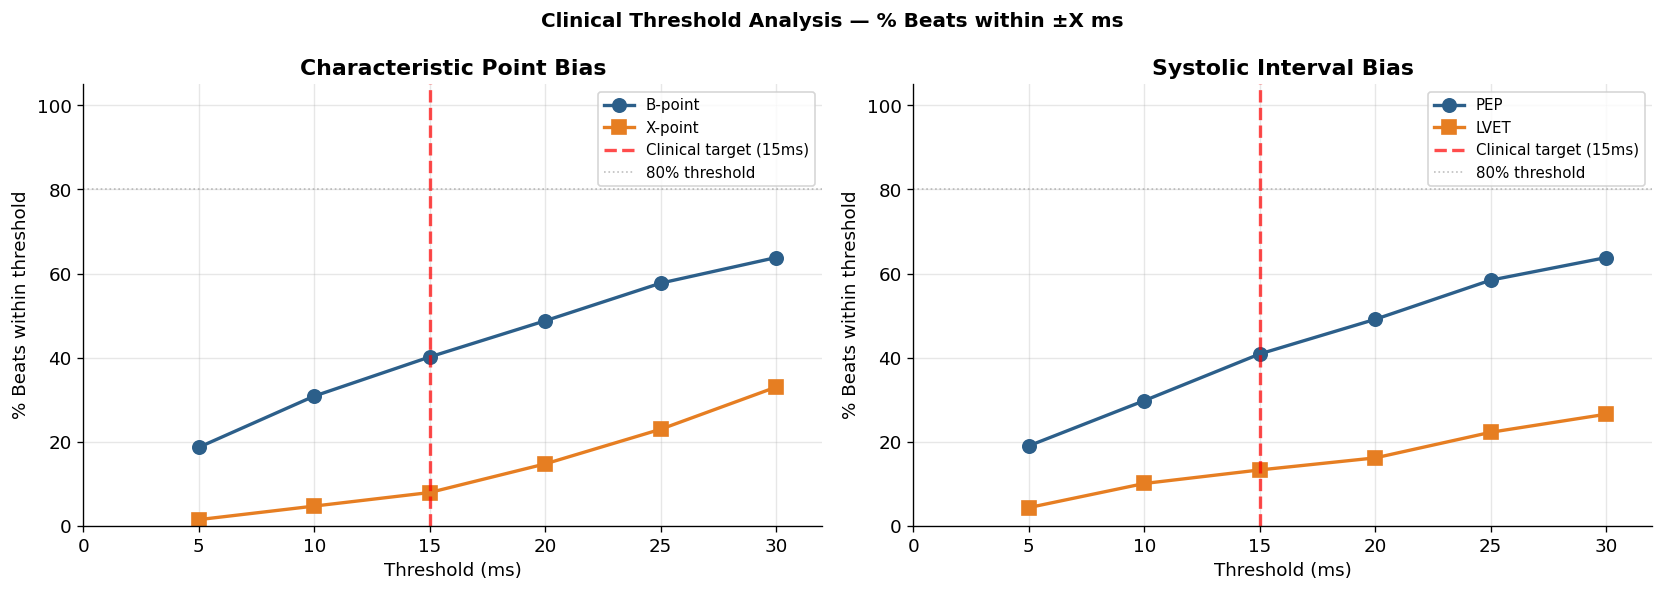


ICG performance at ±15ms clinical target (BEFORE our bias-correction model):
  B-point   : 40.1% within ±15ms ❌ (model needed)
  X-point   : 7.9% within ±15ms ❌ (model needed)
  PEP       : 40.9% within ±15ms ❌ (model needed)
  LVET      : 13.3% within ±15ms ❌ (model needed)


In [10]:
thresholds = [5, 10, 15, 20, 25, 30]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Clinical Threshold Analysis — % Beats within ±X ms', fontsize=12, fontweight='bold')

bias_datasets = {
    'B-point': df_b['b_bias_ms'].dropna().values,
    'X-point': df_x['x_bias_ms'].dropna().values,
    'PEP':     df_pep['pep_bias_ms'].dropna().values if len(df_pep) > 0 else np.array([]),
    'LVET':    df_lvet['lvet_bias_ms'].dropna().values if len(df_lvet) > 0 else np.array([]),
}

line_styles = ['-o', '-s', '-^', '-d']
colors_list = ['#2C5F8A', '#E67E22', '#8E44AD', '#27AE60']

for ax, bias_subset, title in [
    (axes[0], ['B-point','X-point'], 'Characteristic Point Bias'),
    (axes[1], ['PEP','LVET'],        'Systolic Interval Bias'),
]:
    for ls, color, label in zip(line_styles, colors_list, bias_subset):
        arr = bias_datasets[label]
        if len(arr) == 0: continue
        pcts = [np.mean(np.abs(arr) < t)*100 for t in thresholds]
        ax.plot(thresholds, pcts, ls, color=color, linewidth=2, markersize=8, label=label)
        
    ax.axvline(15, color='red', linewidth=2, linestyle='--', alpha=0.7, label='Clinical target (15ms)')
    ax.axhline(80, color='gray', linewidth=1, linestyle=':', alpha=0.5, label='80% threshold')
    ax.set_xlabel('Threshold (ms)')
    ax.set_ylabel('% Beats within threshold')
    ax.set_title(title, fontweight='bold')
    ax.set_xlim(0, max(thresholds)+2)
    ax.set_ylim(0, 105)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{EDA_OUTPUT_DIR}/figures/fig4_clinical_thresholds.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nICG performance at ±15ms clinical target (BEFORE our bias-correction model):')
for label, arr in bias_datasets.items():
    if len(arr) == 0: continue
    pct = np.mean(np.abs(arr) < 15)*100
    status = '✅' if pct > 80 else '❌ (model needed)'
    print(f'  {label:10s}: {pct:.1f}% within ±15ms {status}')

## 5. Mean Waveform Templates
Visualize what the average ICG and ECG beat looks like, and where the
characteristic points and ground truth events land on average.

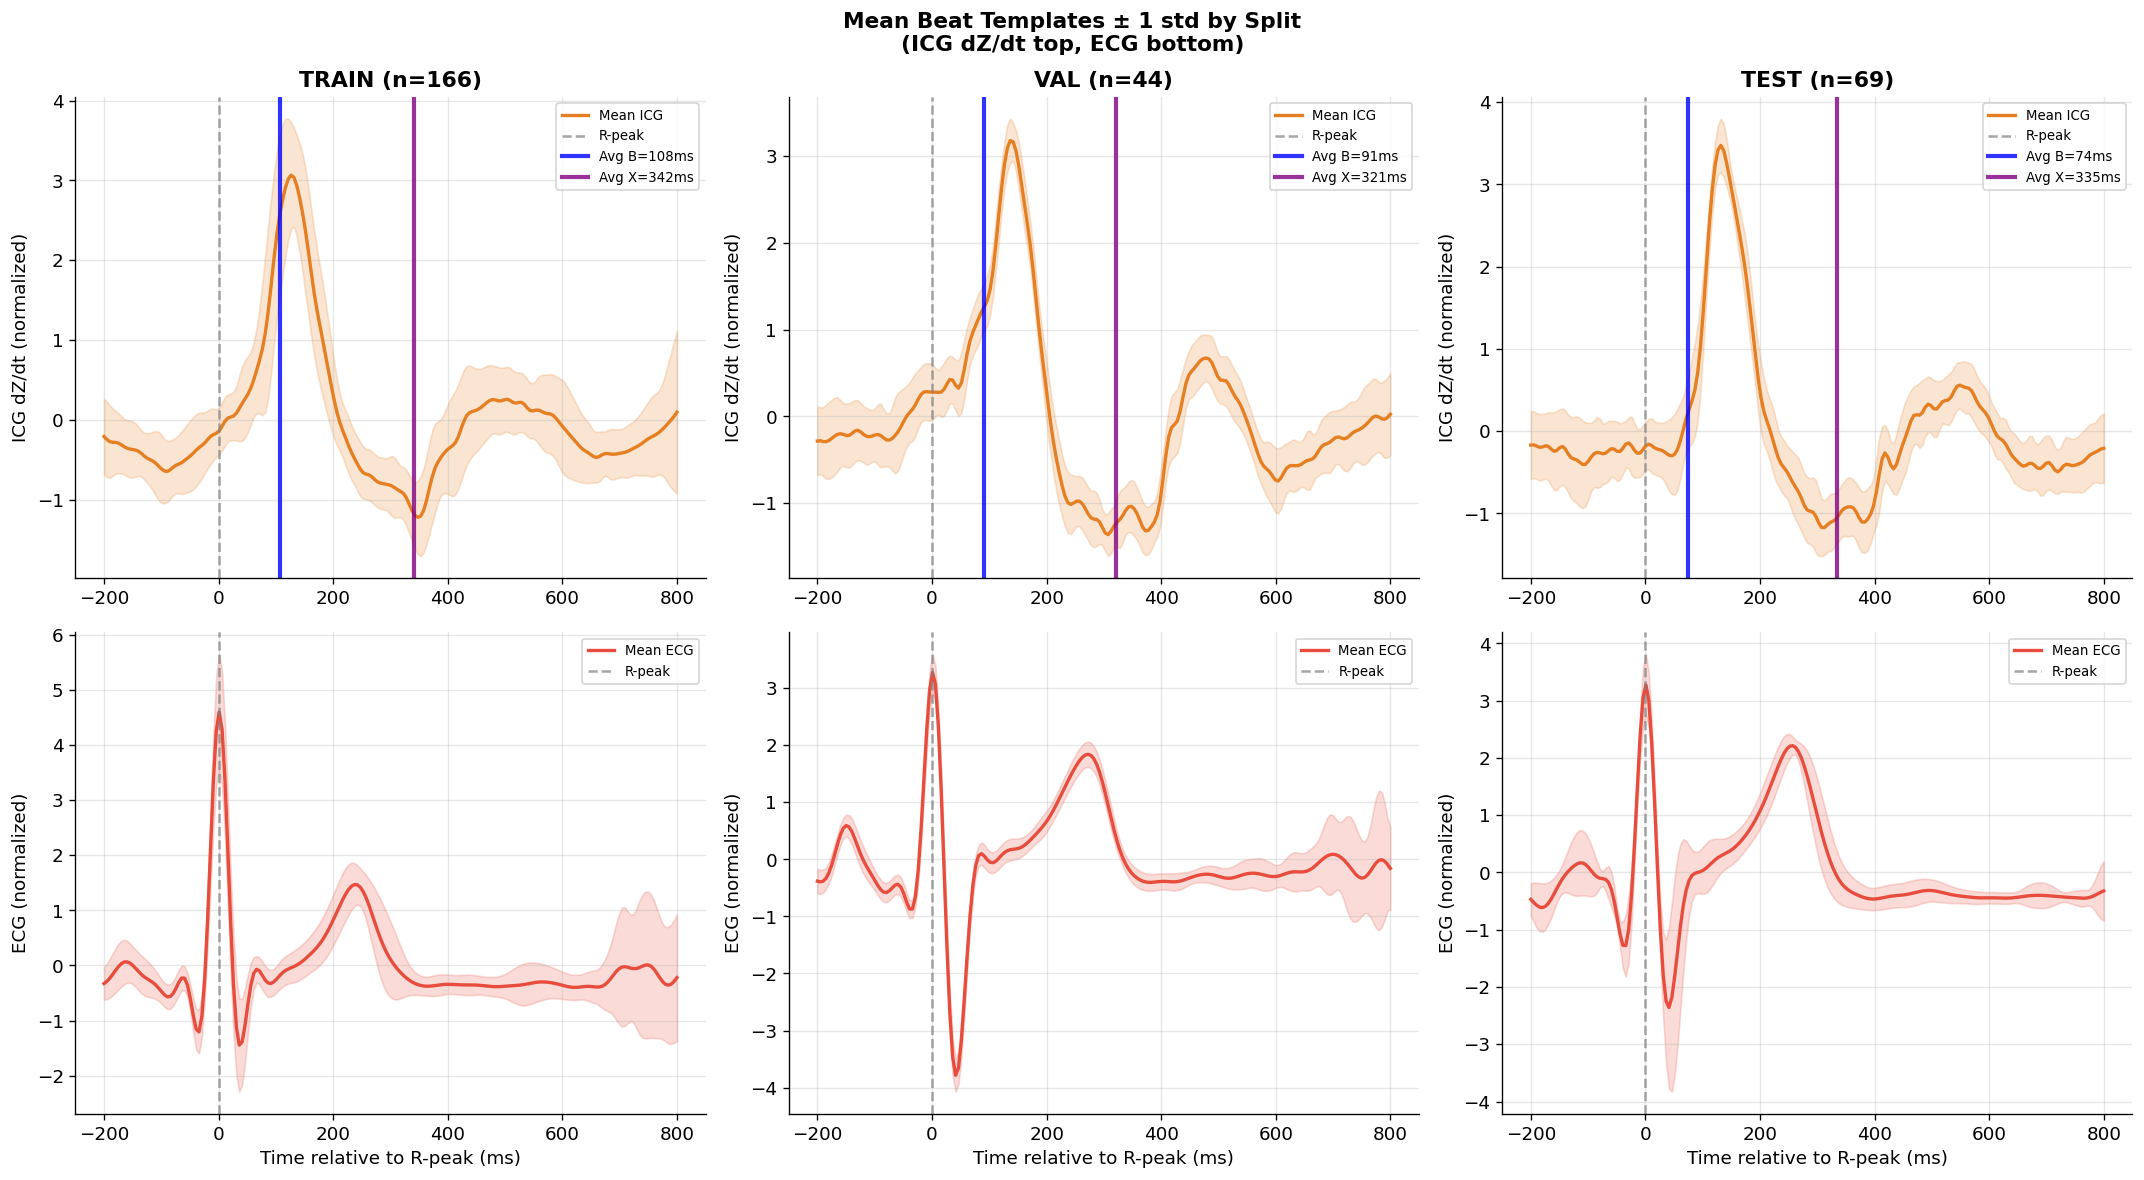

In [11]:
# Load signal windows from final dataset
split_templates = {}
for split in ['train', 'val', 'test']:
    try:
        d = final_dir / split
        icg = np.load(d / 'X_icg.npy')
        ecg = np.load(d / 'X_ecg.npy')
        cp  = np.load(d / 'cp_indices.npy')  # [R_idx, B_idx, X_idx]
        split_templates[split] = {'icg': icg, 'ecg': ecg, 'cp': cp}
    except FileNotFoundError:
        pass

WIN_LEN = 200
PRE_R   = 200
POST_R  = 800
t_win   = np.linspace(-PRE_R, POST_R, WIN_LEN)
R_IDX   = 40

fig, axes = plt.subplots(2, len(split_templates), figsize=(6*len(split_templates), 10))
if len(split_templates) == 1:
    axes = axes.reshape(-1, 1)
fig.suptitle('Mean Beat Templates ± 1 std by Split\n(ICG dZ/dt top, ECG bottom)', 
             fontsize=13, fontweight='bold')

for col, (split, data) in enumerate(split_templates.items()):
    icg_all = data['icg']  # (N, 200)
    ecg_all = data['ecg']
    cp_all  = data['cp']   # (N, 3)
    
    icg_mean = icg_all.mean(axis=0)
    icg_std  = icg_all.std(axis=0)
    ecg_mean = ecg_all.mean(axis=0)
    ecg_std  = ecg_all.std(axis=0)
    
    # Mean characteristic point positions
    valid_b = cp_all[:, 1][cp_all[:, 1] > 0]
    valid_x = cp_all[:, 2][cp_all[:, 2] > 0]
    mean_b_ms = (np.mean(valid_b) - R_IDX) * (1000/200) if len(valid_b) else None
    mean_x_ms = (np.mean(valid_x) - R_IDX) * (1000/200) if len(valid_x) else None
    
    # ICG subplot
    ax = axes[0, col]
    ax.fill_between(t_win, icg_mean-icg_std, icg_mean+icg_std, alpha=0.2, color='#E67E22')
    ax.plot(t_win, icg_mean, color='#E67E22', linewidth=2, label='Mean ICG')
    ax.axvline(0, color='gray', linewidth=1.5, linestyle='--', alpha=0.7, label='R-peak')
    if mean_b_ms:
        ax.axvline(mean_b_ms, color='blue',   linewidth=2.5, alpha=0.8, label=f'Avg B={mean_b_ms:.0f}ms')
    if mean_x_ms:
        ax.axvline(mean_x_ms, color='purple', linewidth=2.5, alpha=0.8, label=f'Avg X={mean_x_ms:.0f}ms')
    ax.set_title(f'{split.upper()} (n={len(icg_all):,})', fontweight='bold')
    ax.set_ylabel('ICG dZ/dt (normalized)')
    ax.legend(fontsize=8)
    
    # ECG subplot
    ax2 = axes[1, col]
    ax2.fill_between(t_win, ecg_mean-ecg_std, ecg_mean+ecg_std, alpha=0.2, color='#E74C3C')
    ax2.plot(t_win, ecg_mean, color='#E74C3C', linewidth=2, label='Mean ECG')
    ax2.axvline(0, color='gray', linewidth=1.5, linestyle='--', alpha=0.7, label='R-peak')
    ax2.set_ylabel('ECG (normalized)')
    ax2.set_xlabel('Time relative to R-peak (ms)')
    ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{EDA_OUTPUT_DIR}/figures/fig5_mean_templates.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Full Dataset Statistics Summary

In [12]:
# Load final dataset stats
try:
    with open(final_dir / 'dataset_stats.json') as f:
        ds_stats = json.load(f)
except:
    ds_stats = {}

print('=' * 65)
print('COMPLETE DATASET STATISTICS SUMMARY')
print('=' * 65)

total_beats = sum(s.get('n_valid', 0) for s in ds_stats.values())
for split, s in ds_stats.items():
    print(f'\n  {split.upper()} split ({len(s.get("subjects",[]))} subjects):')
    print(f'    Raw beats:    {s.get("n_raw", "N/A"):,}')
    print(f'    Valid beats:  {s.get("n_valid", "N/A"):,}')
    print(f'    PEP:          {s.get("pep_mean", 0):.1f} ± {s.get("pep_std", 0):.1f} ms')
    print(f'    LVET:         {s.get("lvet_mean", 0):.1f} ± {s.get("lvet_std", 0):.1f} ms')
    print(f'    Features:     {s.get("n_features", "N/A")} hand-crafted')

print(f'\n  TOTAL valid beats: {total_beats:,}')

print('\n' + '=' * 65)
print('RQ1 CONCLUSIONS')
print('=' * 65)

for name, r in res.items():
    if r.get('n', 0) == 0: continue
    print(f'\n  {name}:')
    print(f'    Mean bias:         {r["mean_ms"]:+.2f} ms (systematic offset)')
    print(f'    Std of bias:       {r["std_ms"]:.2f} ms (random error)')
    print(f'    MAE:               {r["mae_ms"]:.2f} ms')
    print(f'    95% LoA:           [{r["loa_lower"]:.1f}, {r["loa_upper"]:.1f}] ms')
    print(f'    % within ±15ms:    {r["pct_15ms"]:.1f}%')
    status = 'Already meets' if r['mae_ms'] < 15 else 'FAILS — correction needed'
    print(f'    Clinical target:   {status}')

print('\n' + '=' * 65)
print('RESEARCH QUESTION READINESS')
print('=' * 65)
print('  RQ1 ✅  Bias quantified — see bias_summary.csv and figures/')
print('  RQ2 →  Use X_features.npy with RF/SVR/XGBoost for baseline ML')
print('  RQ3 →  Use X_icg.npy with LSTM/CNN-LSTM for deep learning')
print('  RQ4 →  Compare X_icg vs X_ecg vs X_multi for modality ablation')
print('  RQ5 →  Use X_multi.npy with cross-modal attention model')
print('  RQ6 →  Use cp_indices.npy to validate attention patterns')
print()
print('✅ NOTEBOOK 4 COMPLETE — Dataset preparation pipeline DONE!')
print(f'   All EDA figures saved to {EDA_OUTPUT_DIR}/figures/')

COMPLETE DATASET STATISTICS SUMMARY

  TRAIN split (12 subjects):
    Raw beats:    1,013
    Valid beats:  166
    PEP:          63.7 ± 10.8 ms
    LVET:         254.8 ± 31.9 ms
    Features:     30 hand-crafted

  VAL split (1 subjects):
    Raw beats:    114
    Valid beats:  44
    PEP:          75.5 ± 7.3 ms
    LVET:         248.1 ± 12.1 ms
    Features:     30 hand-crafted

  TEST split (2 subjects):
    Raw beats:    173
    Valid beats:  69
    PEP:          77.1 ± 18.1 ms
    LVET:         271.5 ± 11.5 ms
    Features:     30 hand-crafted

  TOTAL valid beats: 279

RQ1 CONCLUSIONS

  B-point:
    Mean bias:         +29.39 ms (systematic offset)
    Std of bias:       59.65 ms (random error)
    MAE:               43.75 ms
    95% LoA:           [-87.5, 146.3] ms
    % within ±15ms:    40.1%
    Clinical target:   FAILS — correction needed

  X-point:
    Mean bias:         +12.88 ms (systematic offset)
    Std of bias:       45.81 ms (random error)
    MAE:               41.9

In [13]:
# Write narrative text report
with open(f'{EDA_OUTPUT_DIR}/bias_report.txt', 'w') as f:
    f.write('HeartCycle — RQ1: ICG Timing Bias Analysis Report\n')
    f.write('=' * 55 + '\n\n')
    f.write(f'Dataset: {len(df):,} beats, {df["subject_id"].nunique()} subjects\n\n')
    
    for name, r in res.items():
        if r.get('n', 0) == 0: continue
        f.write(f'{name}:\n')
        f.write(f'  N={r["n"]:,} | mean={r["mean_ms"]:+.2f}ms | '
                f'std={r["std_ms"]:.2f}ms | MAE={r["mae_ms"]:.2f}ms\n')
        f.write(f'  95% LoA=[{r["loa_lower"]:.1f}, {r["loa_upper"]:.1f}]ms | '
                f'{r["pct_15ms"]:.1f}% within ±15ms\n')
        status = 'MEETS' if r['mae_ms'] < 15 else 'FAILS'
        f.write(f'  Clinical target MAE<15ms: {status}\n\n')
    
    if ba_results:
        f.write('Correlation analysis:\n')
        for label, r in ba_results.items():
            f.write(f'  {label}: r={r["pearson_r"]:.3f}, CCC={r["ccc"]:.3f}\n')

print(f'bias_report.txt written to {EDA_OUTPUT_DIR}/')

bias_report.txt written to ./output/eda/


In [14]:
print('Subjects included:', sorted(df['subject_id'].unique()))

Subjects included: ['CHC01', 'CHC02', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC12', 'CHC14', 'CHC16', 'CHC17']
